# ENVS 117 · Week 4 Tuesday · In-class exercises

40 minutes, in pairs. Run the setup cell first.
V1 (10 min) practices pandas on a familiar table, V2 (15 min) joins a table to polygons by a key, V3 (15 min) takes a new messy file all the way to a map.

Name: Asha L.

In [1]:
from pathlib import Path
from urllib.request import urlretrieve

import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

# Public course data from the textbook's data repository (Wu, Introduction to GIS Programming)
BASE = "https://github.com/opengeos/datasets/releases/download/"
Path("data").mkdir(exist_ok=True)
for f in ["us/cities.csv", "us/us_counties.geojson", "us/us_states.geojson"]:
    out = Path("data") / f.split("/")[-1]
    if not out.exists():          # skip files you already downloaded in Week 3
        urlretrieve(BASE + f, out)

# Two small practice tables written straight to data/.
# Site locations are approximate; PM2.5, temperature and oxygen values are made up for practice.
MONITORS_CSV = """site_id,site_name,county,latitude,longitude,pm25
SJ01,San Jose - Jackson St,Santa Clara,37.3485,-121.8950,48.6
SJ02,San Jose - Knox Ave,santa clara ,37.3381,-121.8499,52.1
GIL1,Gilroy,Santa Clara County,37.0001,-121.5747,61.3
LGT1,Los Gatos,Santa Clara,37.2267,-121.9796,44.0
RWC1,Redwood City,San Mateo,37.4828,-122.2022,39.8
HMB1,Half Moon Bay,San Mateo,37.4636,-122.4286,no data
SF01,San Francisco - Arkansas St,San Francisco,37.7658,-122.3978,41.2
OAK1,Oakland West,Alameda,37.8148,-122.2823,45.7
OAK2,Oakland - Laney College,ALAMEDA,37.7934,-122.2633,47.9
BRK1,Berkeley - Aquatic Park,Alameda,37.8645,-122.3028,43.5
FRE1,Fremont - Chapel Way,Alameda,37.5359,-121.9618,50.4
LIV1,Livermore,Alameda,37.6875,-121.7842,66.8
CON1,Concord,Contra Costa,37.9361,-122.0262,58.2
SPB1,San Pablo,Contra Costa,37.9604,-122.3571,
BTH1,Bethel Island,Contra Costa,38.0064,-121.6419,63.5
SRF1,San Rafael,Marin,37.9722,-122.5189,35.1
VAL1,Vallejo,Solano,38.1027,-122.2378,40.3
VAC1,Vacaville,Solano,38.3524,-121.9601,55.6
NAP1,Napa,Napa,38.3110,-122.2961,37.9
SRO1,Santa Rosa,Sonoma,38.4436,-122.7101,33.4
SEB1,Sebastopol,Sonoma,38.4031,-122.8187,30.2
"""
CREEKS_CSV = """site_id,creek,latitude,longitude,water_temp_c,do_mg_l
GUA1,Guadalupe River,37.3330,-121.9000,21.4,6.4
GUA2,guadalupe river ,37.3700,-121.9330,22.9,4.6
GUA3,Guadalupe River,37.2750,-121.8730,18.2,7.9
COY1,Coyote Creek,37.2760,-121.8050,19.6,6.9
COY2,Coyote creek,37.3550,-121.8790,23.5,4.1
COY3,COYOTE CREEK,37.4120,-121.9230,24.1,--
LGC1,Los Gatos Creek,37.2350,-121.9630,16.8,8.6
LGC2,Los Gatos Creek,37.3150,-121.9020,20.7,7.0
STV1,Stevens Creek,37.3260,-122.0620,15.9,8.2
STV2, Stevens Creek,37.4040,-122.0700,21.8,5.3
SAR1,Saratoga Creek,37.2700,-122.0230,16.4,8.8
SFQ1,San Francisquito Creek,37.4280,-122.1720,17.3,
UVA1,Uvas Creek,37.0130,-121.5900,18.9,6.3
LLA1,Llagas Creek,37.1300,-121.6500,22.6,4.8
"""
Path("data/bay_area_pm25.csv").write_text(MONITORS_CSV)
Path("data/creek_sites.csv").write_text(CREEKS_CSV)

sorted(p.name for p in Path("data").iterdir())

['bay_area_counties.gpkg',
 'bay_area_pm25.csv',
 'bay_area_pm25.gpkg',
 'cities.csv',
 'creek_sites.csv',
 'creek_sites.gpkg',
 'us_counties.geojson',
 'us_states.geojson']

## V1 · US cities with pandas (10 min) · Wu Ch 14

**1.** Read `data/cities.csv`. Print its shape, column names and dtypes.

In [2]:
# your code here
cities = pd.read_csv("data/cities.csv")
print(cities.shape)
print(cities.columns)
print(cities.dtypes)

(109, 6)
Index(['name', 'sov_a3', 'latitude', 'longitude', 'pop_max', 'region'], dtype='str')
name             str
sov_a3           str
latitude     float64
longitude    float64
pop_max        int64
region           str
dtype: object


**2.** How many cities are in each region? **(see below and refer to comment for answer)**

In [3]:
# your code here
regions = set(cities["region"])
for region in regions:
    region_rows = cities[cities["region"] == region]
    print(f"The {region} region has {len(set(region_rows['name']))} unique cities")

#Another way of finding the answer
print("\n")
city_counts = (cities.groupby("region")["name"]
               .agg(["count"])
               )
print(city_counts)

#The Midwest has 19 cities, the Northeast has 10 cities, the South has 34 cities, and the West has 46 cities.

The West region has 46 unique cities
The Northeast region has 10 unique cities
The Midwest region has 19 unique cities
The South region has 34 unique cities


           count
region          
Midwest       19
Northeast     10
South         34
West          46


**3.** List the cities in the West with `pop_max` above 1,000,000, largest first.

In [4]:
# your code here
west = cities[cities["region"] == "West"]
west.sort_values("pop_max", ascending=False)[["region", "name", "pop_max"]]

,region,name,pop_max
106,West,Los Angeles,12500000
90,West,Phoenix,3551000
100,West,San Francisco,3450000
89,West,Seattle,3074000
91,West,San Diego,2916000
101,West,Denver,2313000
60,West,Portland,1875000
58,West,Las Vegas,1823000
0,West,San Bernardino,1745000
56,West,San Jose,1668000


**4.** For each region, the number of cities and the mean and maximum `pop_max`.

In [5]:
# your code here
pop_max_stats = (cities.groupby("region")["pop_max"]
               .agg(["mean", "max"])
               .round(1)
               .sort_values("mean", ascending=False))

city_counts = (cities.groupby("region")["name"]
               .agg(["count"])
               .round(1)
               )

print(pop_max_stats)
print("\n")
print(city_counts)

                mean       max
region                        
Northeast  3440642.6  19040000
Midwest    1493119.5   8990000
South      1375747.1   5585000
West        962711.4  12500000


           count
region          
Midwest       19
Northeast     10
South         34
West          46


**5.** The five largest cities in each region. Hint: sort first, then `groupby("region").head(5)`.

In [6]:
# your code here
descend = cities.sort_values("pop_max", ascending=False)[["region", "name", "pop_max"]]
print(descend.groupby("region").head(5).sort_values("region", ascending=False))


        region             name   pop_max
100       West    San Francisco   3450000
91        West        San Diego   2916000
89        West          Seattle   3074000
106       West      Los Angeles  12500000
90        West          Phoenix   3551000
103      South            Miami   5585000
94       South           Dallas   4798000
104      South          Atlanta   4506000
102      South          Houston   4459000
107      South  Washington D.C.   4338000
108  Northeast         New York  19040000
77   Northeast       Pittsburgh   1838000
1    Northeast       Bridgeport   1018000
95   Northeast           Boston   4467000
97   Northeast     Philadelphia   5492000
87     Midwest      Minneapolis   2616000
92     Midwest        St. Louis   2199000
70     Midwest        Cleveland   1890000
105    Midwest          Chicago   8990000
98     Midwest          Detroit   4101000


**6.** Add a column `pop_millions` rounded to 2 decimals.

In [7]:
# your code here
cities["pop_millions"] = round(cities["pop_max"]/1000000,2)
print(cities)

                name sov_a3  latitude  longitude   pop_max     region  \
0     San Bernardino    USA  34.12038 -117.30003   1745000       West   
1         Bridgeport    USA  41.17998  -73.19996   1018000  Northeast   
2          Rochester    USA  43.17043  -77.61995    755000  Northeast   
3           St. Paul    USA  44.94399  -93.08497    734854    Midwest   
4           Billings    USA  45.78830 -108.54000    104552       West   
..               ...    ...       ...        ...       ...        ...   
104          Atlanta    USA  33.83001  -84.39995   4506000      South   
105          Chicago    USA  41.82999  -87.75005   8990000    Midwest   
106      Los Angeles    USA  33.98998 -118.17998  12500000       West   
107  Washington D.C.    USA  38.89955  -77.00942   4338000      South   
108         New York    USA  40.74998  -73.98002  19040000  Northeast   

     pop_millions  
0            1.74  
1            1.02  
2            0.76  
3            0.73  
4            0.10  
.. 

## V2 · Bay Area population density (15 min) · merge + area

Run this cell to create the population table.

In [8]:
# 2020 Census population of the nine Bay Area counties
pop = pd.DataFrame({
    "county": ["Alameda County", "Contra Costa County", "Marin County", "Napa County",
               "San Francisco County", "San Mateo County", "Santa Clara County",
               "Solano County", "Sonoma County"],
    "pop2020": [1682353, 1165927, 262321, 138019, 873965, 764442, 1936259, 453491, 488863],
})
pop

,county,pop2020
0,Alameda County,1682353
1,Contra Costa County,1165927
2,Marin County,262321
3,Napa County,138019
4,San Francisco County,873965
5,San Mateo County,764442
6,Santa Clara County,1936259
7,Solano County,453491
8,Sonoma County,488863


**1.** Read `data/us_counties.geojson` and keep California (`STATE == "06"`). Call it `ca`.

In [9]:
# your code here
counties = gpd.read_file("data/us_counties.geojson")
ca = counties[counties["STATE"] == "06"]

**2.** Try `ca.merge(pop, left_on="NAME", right_on="county")`. How many rows come back? Why? **See below, answer in comments.**

In [10]:
# your code here
print(ca.head(3))
print("\n")
ca_merged = ca.merge(pop, left_on="NAME", right_on="county")
print(ca_merged.head(3))
#No rows came back because they were unable to find matches in the merge. There is no name column in pop.

             GEO_ID STATE COUNTY           NAME    LSAD  CENSUSAREA  \
186  0500000US06035    06    035         Lassen  County    4541.184   
187  0500000US06049    06    049          Modoc  County    3917.770   
188  0500000US06075    06    075  San Francisco  County      46.873   

                                              geometry  
186  MULTIPOLYGON (((-119.99867 40.77952, -119.9984...  
187  MULTIPOLYGON (((-120.48822 41.99374, -120.3285...  
188  MULTIPOLYGON (((-123.01392 37.70035, -123.0139...  


Empty GeoDataFrame
Columns: [GEO_ID, STATE, COUNTY, NAME, LSAD, CENSUSAREA, geometry, county, pop2020]
Index: []


**3.** Make a `NAME` column in `pop` without the " County" suffix, then merge with `ca` on the left. Check that you get 9 rows and that the result is still a GeoDataFrame. What happens if you write `pop.merge(ca, ...)` instead? **Answered in a comment (see below).**

In [11]:
# your code here
names = list()
for county in pop["county"]:
    names.append(county.split(" County")[0])
pop["NAME"] = names
print(pop)

#pop.merge(ca,....) leads to an error because in ca the county column is "COUNTY" and it is case sensitive for names. 
#For them to both work, they both need to be merged on name. 

ca_merged = ca.merge(pop, on="NAME")
print(ca_merged.shape)
print(type(ca_merged))

                 county  pop2020           NAME
0        Alameda County  1682353        Alameda
1   Contra Costa County  1165927   Contra Costa
2          Marin County   262321          Marin
3           Napa County   138019           Napa
4  San Francisco County   873965  San Francisco
5      San Mateo County   764442      San Mateo
6    Santa Clara County  1936259    Santa Clara
7         Solano County   453491         Solano
8         Sonoma County   488863         Sonoma
(9, 9)
<class 'geopandas.geodataframe.GeoDataFrame'>


**4.** Reproject to California Albers (EPSG:3310). Add `area_km2` and `density` (people per km²). Which county is the densest and which the least dense? **Answered in a comment.**

In [12]:
# your code here
ca_merged = ca_merged.to_crs(epsg=3310)
ca_merged["area_km2"] = ca_merged.geometry.area / 1000000
ca_merged["density"] = ca_merged["pop2020"] / ca_merged["area_km2"]

print(ca_merged[["county", "pop2020", "area_km2", "density"]].sort_values("density", ascending=False))

#San Fracisco County is the most dense and Napa County is the least dense. 


                 county  pop2020     area_km2      density
0  San Francisco County   873965   128.727244  6789.277640
2        Alameda County  1682353  1959.673870   858.486213
6      San Mateo County   764442  1194.497191   639.969692
3   Contra Costa County  1165927  1969.362701   592.032641
7    Santa Clara County  1936259  3377.617513   573.261772
1         Solano County   453491  2298.717157   197.280034
4          Marin County   262321  1412.596901   185.701243
8         Sonoma County   488863  4117.637206   118.724156
5           Napa County   138019  2042.412939    67.576442


**5.** Save `bay` as `data/bay_area_counties.gpkg`. You need this file on Thursday.

In [13]:
# your code here
bay = ca_merged.rename(columns={"COUNTY": "county_fips"})
bay.to_file("data/bay_area_counties.gpkg")

## V3 · Creek water quality, table to map (15 min) · clean + GeoDataFrame

**1.** Read `data/creek_sites.csv` and run `.info()`. Which column should be numbers but is not? Which column has messy text? **Answered in a comment.**

In [14]:
# your code here
creek = pd.read_csv("data/creek_sites.csv")
print(creek.info)
print(creek.dtypes)

#The do_mg_l column is a str but should be a float. The creek column has messy text with different
#punctuation for different names. 

<bound method DataFrame.info of    site_id                   creek  latitude  longitude  water_temp_c do_mg_l
0     GUA1         Guadalupe River    37.333   -121.900          21.4     6.4
1     GUA2        guadalupe river     37.370   -121.933          22.9     4.6
2     GUA3         Guadalupe River    37.275   -121.873          18.2     7.9
3     COY1            Coyote Creek    37.276   -121.805          19.6     6.9
4     COY2            Coyote creek    37.355   -121.879          23.5     4.1
5     COY3            COYOTE CREEK    37.412   -121.923          24.1      --
6     LGC1         Los Gatos Creek    37.235   -121.963          16.8     8.6
7     LGC2         Los Gatos Creek    37.315   -121.902          20.7     7.0
8     STV1           Stevens Creek    37.326   -122.062          15.9     8.2
9     STV2           Stevens Creek    37.404   -122.070          21.8     5.3
10    SAR1          Saratoga Creek    37.270   -122.023          16.4     8.8
11    SFQ1  San Francisquito Cre

**2.** Clean `creek` (strip spaces, title case) and convert `do_mg_l` to numbers. How many readings are missing? Drop them. **Question answered in a comment.**

In [15]:
# your code here
creek["creek"] = creek["creek"].str.strip().str.title()
creek["do_mg_l"] = pd.to_numeric(creek["do_mg_l"], errors='coerce')

print(creek.isna().sum())
print(creek[creek["do_mg_l"].isna()])
creek = creek.dropna()
#Two readings from do_mg_l are missing.

site_id         0
creek           0
latitude        0
longitude       0
water_temp_c    0
do_mg_l         2
dtype: int64
   site_id                   creek  latitude  longitude  water_temp_c  do_mg_l
5     COY3            Coyote Creek    37.412   -121.923          24.1      NaN
11    SFQ1  San Francisquito Creek    37.428   -122.172          17.3      NaN


**3.** Dissolved oxygen below 5 mg/L stresses fish such as steelhead. Add a column `low_do`. How many sites are low, and on which creeks? **Question answered in a comment (see below).** 

In [16]:
# your code here

creek["low_do"] = creek["do_mg_l"] < 5
print(creek["low_do"].info)

low_sites = creek[creek["low_do"] == True]
print(f"\nNumber of sites that are low: {len(low_sites)}\n")
print(f"Names of sites that are low:\n {low_sites['creek']}")

#There are three sites that are low, which include the Guadalupe River, Coyote Creek, and Llagas Creek. 

<bound method Series.info of 0     False
1      True
2     False
3     False
4      True
6     False
7     False
8     False
9     False
10    False
12    False
13     True
Name: low_do, dtype: bool>

Number of sites that are low: 3

Names of sites that are low:
 1     Guadalupe River
4        Coyote Creek
13       Llagas Creek
Name: creek, dtype: str


**4.** For each creek: number of sites, mean temperature and minimum dissolved oxygen.

In [17]:
# your code here
creek.groupby("creek").agg(
    num_sites = ("site_id", "count"),
    mean_temp = ("water_temp_c", "mean"), 
    do_min = ("do_mg_l", "min")
)

,num_sites,mean_temp,do_min
creek,,,
Coyote Creek,2,21.550000,4.1
Guadalupe River,3,20.833333,4.6
Llagas Creek,1,22.600000,4.8
Los Gatos Creek,2,18.750000,7.0
Saratoga Creek,1,16.400000,8.8
Stevens Creek,2,18.850000,5.3
Uvas Creek,1,18.900000,6.3


**5.** Make a GeoDataFrame in EPSG:4326 and save it as `data/creek_sites.gpkg`. Read it back and print its CRS.

In [18]:
# your code here
creek_gdf = gpd.GeoDataFrame(
    creek,
    geometry=gpd.points_from_xy(creek["longitude"], creek["latitude"]),   # x is longitude
    crs="EPSG:4326",
)

creek_gdf.to_file("data/creek_sites.gpkg")

creek_read = gpd.read_file("data/creek_sites.gpkg")
print(creek_read.crs)

EPSG:4326


**6.** Map the sites over Santa Clara County, colored by dissolved oxygen. **Discuss:** warm water holds less oxygen. Do the low-oxygen sites look warmer? **Answered in a comment (refer below).**

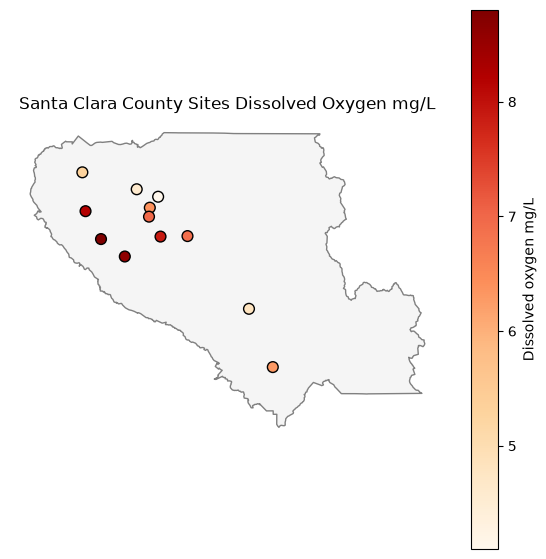

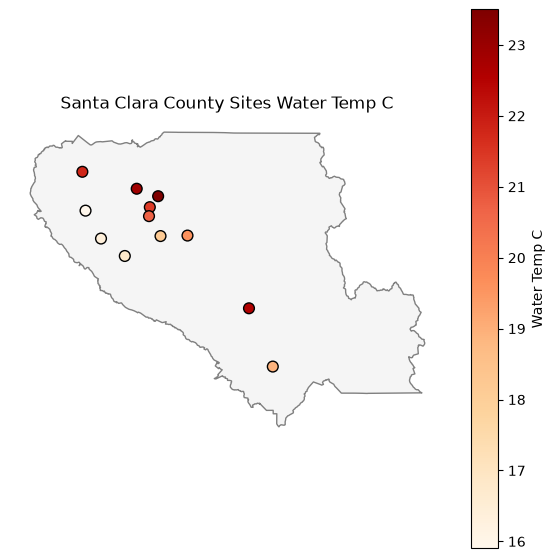

In [25]:
# your code here
santa_clara = ca[ca["NAME"] == "Santa Clara"]
santa_clara = santa_clara.to_crs(creek_read.crs)

#Dissolved Oxygen
ax = santa_clara.plot(color="whitesmoke", edgecolor="gray", figsize=(7, 7))
creek_read.plot(ax=ax, column="do_mg_l", cmap="OrRd", markersize=60, edgecolor="black", legend=True,
         legend_kwds={"label": "Dissolved oxygen mg/L"})
ax.set_axis_off()
ax.set_title("Santa Clara County Sites Dissolved Oxygen mg/L")
plt.show()

#Water Temperature
ax = santa_clara.plot(color="whitesmoke", edgecolor="gray", figsize=(7, 7))
creek_read.plot(ax=ax, column="water_temp_c", cmap="OrRd", markersize=60, edgecolor="black", legend=True,
         legend_kwds={"label": "Water Temp C"})
ax.set_axis_off()
ax.set_title("Santa Clara County Sites Water Temp C")
plt.show()

#Discussion Answer: After mapping sites with dissolved oxygen and sites with water temperature,bit does appear that many sites that have lower dissolved
#oxygen levels (first map) may also have higher water temperatures (second map). 